In [1]:
# Si estás en un entorno limpio, descomenta las instalaciones:
# !pip install opencv-python torch torchvision torchaudio matplotlib numpy

import math, os, cv2, numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)


Device: cuda


In [2]:
def _ensure_odd(k: int) -> int:
    return k if k % 2 == 1 else k + 1

class CWT1D(nn.Module):
    """
    CWT 1D con Morlet COMPLEJA corregida (ideal para video deepfakes).
    Defaults pensados para ~30 FPS, 32–48 frames, ROI facial.

    Salida: magnitud |W| [B,S,T] (y opcionalmente fase).
    """
    def __init__(
        self,
        fs: float = 30.0,
        kernel_size: int = 161,
        w0: float = 6.5,
        scales=None,
        freqs_hz=None,
        fmin: float = 0.5,
        fmax: float = 12.0,
        n_bands: int = 16,
        norm_mode: str = "l2",
        pad_mode: str = "reflect",
        return_phase: bool = False,
    ):
        super().__init__()
        self.fs = float(fs) if fs is not None else None
        self.kernel_size = _ensure_odd(int(kernel_size))
        self.w0 = float(w0)
        self.return_phase = bool(return_phase)
        self.norm_mode = norm_mode
        self.pad_mode = pad_mode

        if (scales is None) and (freqs_hz is None):
            assert self.fs is not None, "Debes indicar fs para bandas por frecuencia."
            freqs_hz = torch.logspace(
                math.log10(fmin), math.log10(fmax), steps=int(n_bands)
            ).tolist()

        if scales is None:
            assert self.fs is not None, "Para freqs_hz necesitas fs."
            scales = [self.w0 / (2.0 * math.pi * float(f)) for f in freqs_hz]

        self.register_buffer("scales", torch.tensor(scales, dtype=torch.float32), persistent=False)

        self.corr_const = math.exp(-0.5 * (self.w0 ** 2))  # Morlet corregida
        self.pi_norm = math.pi ** (-0.25)

        self._built = False
        self.register_buffer("Kr", None, persistent=False)
        self.register_buffer("Ki", None, persistent=False)

    def _build_kernels(self, device, dtype, dt: float):
        S = self.scales.to(device=device, dtype=torch.float32)
        K = self.kernel_size
        half = K // 2
        t = torch.arange(-half, half + 1, device=device, dtype=torch.float32) * dt  # [K]

        kernels_r, kernels_i = [], []
        for s in S:
            gauss = torch.exp(-0.5 * (t / s) ** 2)
            carrier = torch.exp(1j * (self.w0 * (t / s)))
            psi = (self.pi_norm / torch.sqrt(s)) * (carrier - self.corr_const) * gauss
            psi = psi.flip(0)  # correlación
            kernels_r.append(psi.real.view(1, 1, K))
            kernels_i.append(psi.imag.view(1, 1, K))

        Kr = torch.cat(kernels_r, dim=0)  # [S,1,K]
        Ki = torch.cat(kernels_i, dim=0)  # [S,1,K]

        if self.norm_mode == "l2":
            energy = torch.sqrt((Kr**2 + Ki**2).sum(dim=(1, 2), keepdim=True) + 1e-12)
            Kr = Kr / energy
            Ki = Ki / energy
        elif self.norm_mode != "none":
            raise ValueError(f"norm_mode desconocido: {self.norm_mode}")

        self.Kr = Kr.to(device=device, dtype=dtype)
        self.Ki = Ki.to(device=device, dtype=dtype)
        self._built = True

    def forward(self, x: torch.Tensor, dt: float = None):
        assert x.dim() == 3 and x.size(1) == 1, "Se espera [B,1,T]."
        device, dtype = x.device, x.dtype
        if dt is None:
            dt = 1.0 / self.fs if self.fs is not None else 1.0
        dt = float(dt)

        if (not self._built) or (self.Kr is None) or (self.Kr.device != device) or (self.Kr.dtype != dtype):
            self._build_kernels(device, dtype, dt)

        pad = self.kernel_size // 2
        T = x.size(-1)

        # reflect/replicate requieren pad < T; si no, hacemos fallback a padding interno de conv1d
        can_explicit_pad = (self.pad_mode is not None) and (pad < T)

        if can_explicit_pad:
            x_pad = F.pad(x, (pad, pad), mode=self.pad_mode)
            conv_pad = 0
        else:
            x_pad = x
            conv_pad = pad  # zero-padding interno de conv1d (si self.pad_mode es None o pad>=T)

        yr = F.conv1d(x_pad, self.Kr, padding=conv_pad)
        yi = F.conv1d(x_pad, self.Ki, padding=conv_pad)
        mag = torch.sqrt(yr**2 + yi**2 + 1e-12)
        if self.return_phase:
            phase = torch.atan2(yi, yr)
            return mag, phase
        return mag



In [3]:
def load_video_frames(path, target_fps=30.0, max_frames=None, resize=(192,192), center_crop_ratio=0.9):
    cap = cv2.VideoCapture(path)
    if not cap.isOpened():
        raise RuntimeError(f"No pude abrir el video: {path}")

    src_fps = cap.get(cv2.CAP_PROP_FPS) or target_fps
    # ratio para saltar frames y aproximar target_fps
    step = max(1, int(round(src_fps / target_fps)))
    frames = []
    idx = 0
    while True:
        ret, frame = cap.read()
        if not ret: break
        if idx % step == 0:
            # BGR->RGB
            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            h, w = frame.shape[:2]
            # center crop cuadrado
            side = int(min(h, w) * center_crop_ratio)
            y0 = (h - side) // 2
            x0 = (w - side) // 2
            crop = frame[y0:y0+side, x0:x0+side]
            # resize
            if resize is not None:
                crop = cv2.resize(crop, resize, interpolation=cv2.INTER_AREA)
            frames.append(crop)
        idx += 1
        if max_frames and len(frames) >= max_frames:
            break
    cap.release()
    frames = np.stack(frames, axis=0)  # [T,H,W,3]
    return frames, target_fps

def to_grayscale(frames):  # [T,H,W,3] -> [T,1,H,W]
    r, g, b = frames[...,0], frames[...,1], frames[...,2]
    y = 0.2989*r + 0.5870*g + 0.1140*b
    y = y.astype(np.float32) / 255.0
    return y[:, None, ...]  # [T,1,H,W]

def detrend_per_pixel(x):  # [T,1,H,W]
    # quitar media temporal por píxel
    mu = x.mean(axis=0, keepdims=True)
    return x - mu


In [4]:
def cwt_over_roi(x_tchw, fps=30.0, cwt_cfg=None):
    """
    x_tchw: [T,1,H,W] en float32 [0..1], ya detrendido
    Devuelve: W_roi [S,T], freqs (Hz)
    """
    T, _, H, W = x_tchw.shape
    # serie 1D: promedio espacial (ROI)
    s = x_tchw.mean(axis=(2,3), keepdims=False)  # [T,1]
    xt = torch.from_numpy(s.T).unsqueeze(0).to(DEVICE)  # [B=1,1,T]
    cwt = CWT1D(fs=fps, **(cwt_cfg or {})).to(DEVICE)
    W = cwt(xt)[0].detach().cpu().numpy()  # [S,T]
    # reconstruir las freqs a partir de escalas
    freqs = (cwt.w0 / (2*np.pi*cwt.scales.cpu().numpy()))
    return W, freqs

def cwt_per_pixel_downsample(x_tchw, fps=30.0, grid=(12,12), cwt_cfg=None):
    """
    Aplica CWT por píxel pero en grilla reducida para costo razonable.
    x_tchw: [T,1,H,W] (float32 detrend)
    grid: (Gh,Gw) parches uniformes; toma el centro de cada celda como 'píxel'
    Devuelve: W_maps [S,T,Gh,Gw], freqs
    """
    T, _, H, W = x_tchw.shape
    Gh, Gw = grid
    ys = np.linspace(0, H-1, Gh, dtype=int)
    xs = np.linspace(0, W-1, Gw, dtype=int)

    series = []
    for y in ys:
        for x in xs:
            series.append(x_tchw[:, 0, y, x])  # [T]
    series = np.stack(series, axis=0).astype(np.float32)  # [Gh*Gw, T]

    xt = torch.from_numpy(series).unsqueeze(1).to(DEVICE)  # [Gh*Gw,1,T]
    cwt = CWT1D(fs=fps, **(cwt_cfg or {})).to(DEVICE)
    W = cwt(xt).detach()  # [Gh*Gw,S,T]
    S = W.shape[1]
    W = W.view(Gh, Gw, S, T).permute(2,3,0,1).contiguous()  # [S,T,Gh,Gw]
    freqs = (cwt.w0 / (2*np.pi*cwt.scales.cpu().numpy()))
    return W.cpu().numpy(), freqs


In [ ]:
def plot_roi_spectrogram(W_roi, freqs, title="CWT ROI (|W|)"):
    plt.figure()
    plt.imshow(W_roi, aspect='auto', origin='lower')
    plt.yticks(
        ticks=np.linspace(0, len(freqs)-1, 6, dtype=int),
        labels=[f"{freqs[i]:.1f} Hz" for i in np.linspace(0, len(freqs)-1, 6, dtype=int)]
    )
    plt.xlabel("Tiempo (frames)")
    plt.ylabel("Frecuencia (Hz) ~")
    plt.title(title)
    plt.tight_layout()
    plt.show()

def plot_roi_spectrogram(W_roi, freqs, title="CWT ROI (|W|)"):
    plt.figure()
    plt.imshow(W_roi, aspect='auto', origin='lower')
    plt.yticks(
        ticks=np.linspace(0, len(freqs)-1, 6, dtype=int),
        labels=[f"{freqs[i]:.1f} Hz" for i in np.linspace(0, len(freqs)-1, 6, dtype=int)]
    )
    plt.xlabel("Tiempo (frames)")
    plt.ylabel("Frecuencia (Hz) ~")
    plt.title(title)
    plt.tight_layout()
    plt.show()

def plot_band_maps(W_maps, freqs, band_indices=(2,5,8)):
    # W_maps: [S,T,Gh,Gw]  -> promediamos en T para ver "energía por banda"
    E = W_maps.mean(axis=1)  # [S,Gh,Gw]
    n = len(band_indices)
    plt.figure(figsize=(4*n, 4))
    for k, bi in enumerate(band_indices, 1):
        plt.subplot(1, n, k)
        plt.imshow(E[bi], origin='lower')
        plt.title(f"Banda {bi} ~ {freqs[bi]:.1f} Hz")
        plt.axis('off')
    plt.suptitle("Energía espacial por banda (promedio en el tiempo)")
    plt.tight_layout()
    plt.show()


In [6]:
def analyze_video_with_cwt(video_path,
                           target_fps=30.0,
                           max_frames=48,
                           resize=(192,192),
                           grid=(12,12),
                           cwt_cfg=None,
                           visualize=True):
    frames_rgb, fps_eff = load_video_frames(video_path, target_fps=target_fps,
                                            max_frames=max_frames, resize=resize)
    x = to_grayscale(frames_rgb)                 # [T,1,H,W] float32
    x = detrend_per_pixel(x)                     # quita media temporal

    # CWT ROI (rápido)
    W_roi, freqs = cwt_over_roi(x, fps=fps_eff, cwt_cfg=cwt_cfg)
    # CWT por píxel downsampleado
    W_maps, freqs2 = cwt_per_pixel_downsample(x, fps=fps_eff, grid=grid, cwt_cfg=cwt_cfg)

    if visualize:
        plot_roi_spectrogram(W_roi, freqs, title="CWT ROI (|W|)")
        plot_chirp_ridge(W_roi, freqs, title="CWT ROI (cresta)")
        # Muestra 3 bandas ejemplo
        sel = np.linspace(1, len(freqs)-2, num=3, dtype=int).tolist()
        plot_band_maps(W_maps, freqs, band_indices=sel)

    # Features sencillas (para una red):
    # - Energía por banda a partir del ROI: mean/var temporal -> [2*S]
    band_mean = W_roi.mean(axis=1)        # [S]
    band_std  = W_roi.std(axis=1)         # [S]
    features = np.concatenate([band_mean, band_std], axis=0).astype(np.float32)  # [2S]

    return {
        "fps": fps_eff,
        "frames": frames_rgb.shape[0],
        "freqs": freqs,
        "W_roi": W_roi,      # [S,T]
        "W_maps": W_maps,    # [S,T,Gh,Gw]
        "features": features # [2S]
    }


In [7]:
# --- Opción A: MLP simple sobre features por banda (demo) ---

class BandMLP(nn.Module):
    def __init__(self, in_dim, hidden=128, num_classes=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden),
            nn.ReLU(inplace=True),
            nn.Dropout(0.2),
            nn.Linear(hidden, hidden),
            nn.ReLU(inplace=True),
            nn.Linear(hidden, num_classes)
        )
    def forward(self, x):
        return self.net(x)

# Uso:
# out = analyze_video_with_cwt(...); x_feat = torch.from_numpy(out["features"]).unsqueeze(0)
# logits = BandMLP(in_dim=len(out["features"]))(x_feat)

# --- Opción B: convertir mapas CWT a tokens para TimeSformer ---

class CWTtoTokens(nn.Module):
    """
    Reduce bandas S y hace patchify para producir tokens alineados con ViT/TimeSformer.
    Entrada:  cwt_feats [B,S,T,H,W]
    Salida:   tokens    [B,T,Np,D]
    """
    def __init__(self, S, patch=1, reduce_channels=64, embed_dim=256):
        super().__init__()
        self.patch = patch
        self.reduce = nn.Conv3d(S, reduce_channels, kernel_size=1)  # S -> Cr
        self.embed_dim = embed_dim
        self.proj = None
        self.reduce_channels = reduce_channels

    def _build_proj(self, H, W, device, dtype):
        ph = pw = self.patch
        in_dim = self.reduce_channels * ph * pw
        # Crea el Linear directamente en el device/dtype del input:
        self.proj = nn.Linear(in_dim, self.embed_dim, bias=True).to(device=device, dtype=dtype)

    def forward(self, cwt_feats):  # [B,S,T,H,W]
        assert cwt_feats.dim() == 5, "cwt_feats debe ser [B,S,T,H,W]"
        device = cwt_feats.device
        dtype  = cwt_feats.dtype

        B,S,T,H,W = cwt_feats.shape

        # reduce canales de bandas
        z = self.reduce(cwt_feats)          # [B,Cr,T,H,W]
        z = z.permute(0,2,1,3,4)            # [B,T,Cr,H,W]

        # construir proj si falta o si está en device/dtype distinto
        if (self.proj is None) or (self.proj.weight.device != device) or (self.proj.weight.dtype != dtype):
            self._build_proj(H, W, device, dtype)

        # patchify por frame (si H,W ya son grilla (Gh,Gw), usa patch=1)
        ph = pw = self.patch
        z = z.unfold(3, ph, ph).unfold(4, pw, pw)   # [B,T,Cr,H/ph,W/pw,ph,pw]
        B,T,Cr,Hn,Wn,ph,pw = z.shape
        z = z.contiguous().view(B, T, Hn*Wn, Cr*ph*pw)  # [B,T,Np,Cr*ph*pw]

        # asegúrate del dtype
        z = z.to(dtype=self.proj.weight.dtype)
        tokens = self.proj(z)                        # [B,T,Np,D]
        return tokens



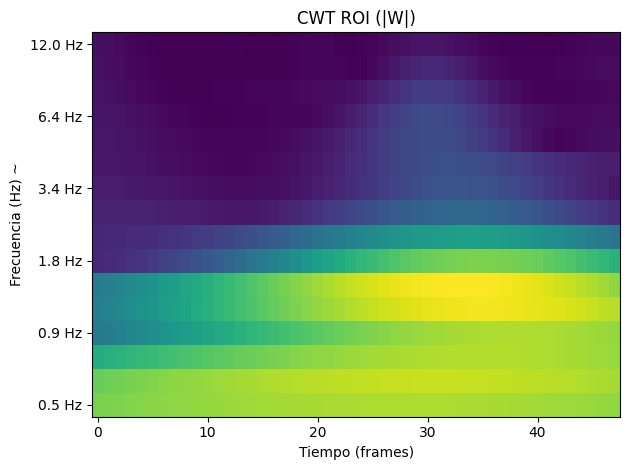

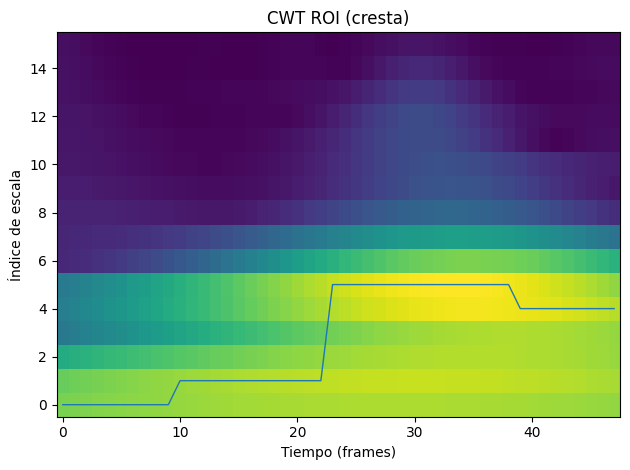

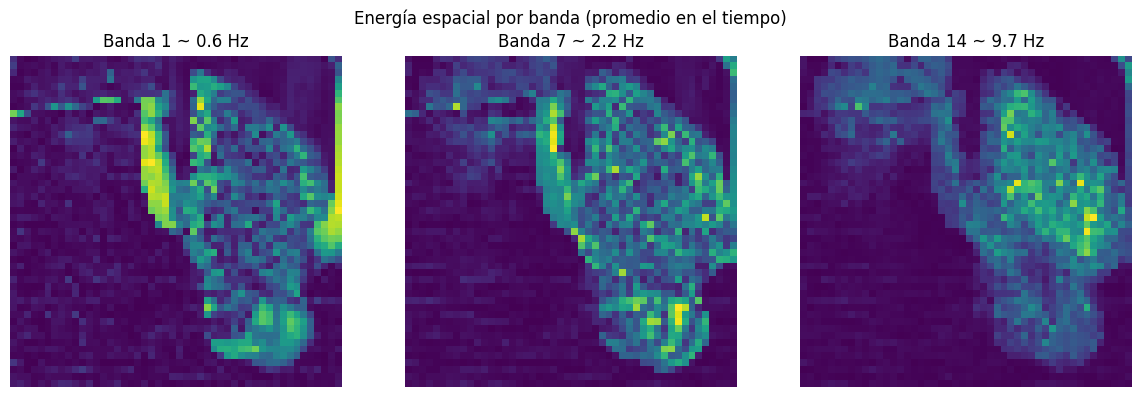

Frames: 48 FPS: 30.0
Bandas: 16 Frecuencias (Hz) ~ [ 0.5   0.62  0.76  0.94  1.17  1.44  1.78  2.2   2.72  3.37  4.16  5.14
  6.36  7.86  9.71 12.  ]
Tokens CWT: torch.Size([1, 48, 2304, 256]) (se concatenar con tokens RGB)


In [8]:
# Cambia la ruta a tu video
#VIDEO_PATH = r"C:\Deepfake\Datasets\FF++\real\01__exit_phone_room.mp4"
VIDEO_PATH = r"C:\Deepfake\Datasets\FF++\real\01__hugging_happy.mp4"
#VIDEO_PATH = r"C:\Deepfake\Datasets\FF++\fake\01_02__exit_phone_room__YVGY8LOK.mp4"
#VIDEO_PATH = r"C:\Deepfake\Datasets\FF++\fake\01_02__hugging_happy__YVGY8LOK.mp4"

out = analyze_video_with_cwt(
    VIDEO_PATH,
    target_fps=30.0,
    max_frames=48,
    resize=(192,192),
    grid=(48,48),   # grilla para cwt por "píxel" (12x12=144 series)
    cwt_cfg=dict(
        # w0=6.5, kernel_size=161, n_bands=16, fmin=0.5, fmax=12.0,
    ),
    visualize=True
)

print("Frames:", out["frames"], "FPS:", out["fps"])
print("Bandas:", len(out["freqs"]), "Frecuencias (Hz) ~", np.round(out["freqs"],2))

# --- Demo tokens para fusión con TimeSformer ---
# Crea un "batch" B=1 con mapas [S,T,Gh,Gw] -> [B,S,T,H,W]
W_maps = torch.from_numpy(out["W_maps"]).unsqueeze(0).to(DEVICE)  # [1,S,T,Gh,Gw]
S = W_maps.shape[1]
tok_proj = CWTtoTokens(S=S, patch=1, reduce_channels=64, embed_dim=256).to(DEVICE)
tokens = tok_proj(W_maps)  # [1,T,Np,256]
print("Tokens CWT:", tokens.shape, "(se concatenar con tokens RGB)")


In [9]:
# ===== HÍBRIDO: FFT pixelwise en grilla, helpers y APM-lite =====

import numpy as np
import torch
import matplotlib.pyplot as plt
import torch.nn as nn

def hyb_make_grid_indices(H, W, Gh, Gw):
    ys = np.linspace(0, H-1, Gh, dtype=int)
    xs = np.linspace(0, W-1, Gw, dtype=int)
    return ys, xs

def hyb_pixelwise_fft_mag_grid(x_tchw, fps, grid=(12,12), window="hann"):
    """
    x_tchw : [T,1,H,W] float32 (idealmente ya detrendido)
    fps    : Hz
    grid   : (Gh,Gw) -> se toma el valor del centro de cada celda de una malla uniforme
    Devuelve:
      Fmag  : [F,Gh,Gw] magnitud FFT por píxel-grid
      freqs : [F] Hz
    """
    T, _, H, W = x_tchw.shape
    Gh, Gw = grid
    ys, xs = hyb_make_grid_indices(H, W, Gh, Gw)

    # extrae series [Gh*Gw, T]
    series = []
    for y in ys:
        for x in xs:
            series.append(x_tchw[:,0,y,x])
    X = np.stack(series, 0).astype(np.float32)         # [P, T], P = Gh*Gw

    # ventana temporal
    if window == "hann":
        w = np.hanning(T).astype(np.float32)[None,:]   # [1,T]
    else:
        w = np.ones((1,T), np.float32)

    Xw = X * w                                        # [P,T]
    Xw_t = torch.from_numpy(Xw)                       # CPU ok
    Xfft = torch.fft.rfft(Xw_t, dim=1)                # [P, F]
    Fmag = torch.abs(Xfft).numpy().astype(np.float32) # [P, F]
    Fmag = Fmag.reshape(Gh, Gw, -1).transpose(2,0,1)  # [F,Gh,Gw]
    freqs = np.fft.rfftfreq(T, d=1.0/float(fps))      # [F]
    return Fmag, freqs

def hyb_band_energy_maps(Fmag, freqs, bands):
    """
    bands: lista de (f0,f1). Devuelve lista de mapas [Gh,Gw] por banda.
    """
    maps = []
    for (f0,f1) in bands:
        m = (freqs>=f0) & (freqs<=f1)
        Em = Fmag[m].sum(axis=0)  # [Gh,Gw]
        maps.append(Em)
    return maps

def hyb_peak_frequency_map(Fmag, freqs, fmin=0.5, fmax=6.0):
    m = (freqs>=fmin) & (freqs<=fmax)
    sub = Fmag[m]                             # [F',Gh,Gw]
    idx = np.argmax(sub, axis=0)              # [Gh,Gw]
    f_map = freqs[m][idx]                     # [Gh,Gw]
    return f_map

def hyb_apm_lite(Fmag, freqs, band_hi=(3.0,10.0), band_lo=(0.2,0.7), topk=5, nms_iou=0.3, box=2):
    """
    APM-lite en grilla: diferencia de energía HF-LF y top-k celdas (con NMS rectangular en la grilla).
    box: lado (en celdas) para NMS; 2~3 suele ir bien en Gh~12
    """
    Gh, Gw = Fmag.shape[1:]
    Mh = Fmag[(freqs>=band_hi[0]) & (freqs<=band_hi[1])].sum(axis=0)  # [Gh,Gw]
    Ml = Fmag[(freqs>=band_lo[0]) & (freqs<=band_lo[1])].sum(axis=0)  # [Gh,Gw]
    score = Mh - Ml

    def iou(b1,b2):
        x11,y11,x12,y12 = b1; x21,y21,x22,y22 = b2
        xa, ya = max(x11,x21), max(y11,y21)
        xb, yb = min(x12,x22), min(y12,y21)
        inter = max(0, xb-xa) * max(0, yb-ya)
        a1 = (x12-x11)*(y12-y11); a2 = (x22-x21)*(y22-y21)
        uni = a1 + a2 - inter + 1e-6
        return inter/uni

    # candidatos por puntuación
    order = np.argsort(-score.reshape(-1))
    boxes, scores = [], []
    taken = []
    for idx in order:
        y, x = divmod(idx, Gw)
        x1 = max(0, x - box//2); y1 = max(0, y - box//2)
        x2 = min(Gw, x1 + box);  y2 = min(Gh, y1 + box)
        cand = (x1,y1,x2,y2)
        ok = True
        for b in taken:
            if iou(cand, b) > nms_iou:
                ok = False; break
        if ok:
            taken.append(cand); boxes.append(cand); scores.append(score[y,x])
            if len(boxes) >= topk: break
    return boxes, scores, score

def hyb_plot_band_maps(band_maps, bands, title="FFT pixelwise — Energía por banda (grilla)"):
    n = len(band_maps)
    plt.figure(figsize=(4*n,4))
    for i,(E,(f0,f1)) in enumerate(zip(band_maps,bands),1):
        plt.subplot(1,n,i)
        plt.imshow(E, origin='lower'); plt.axis('off')
        plt.title(f"{f0:.1f}-{f1:.1f} Hz")
    plt.suptitle(title); plt.tight_layout(); plt.show()

def hyb_draw_apm_boxes_on_grid(score_map, boxes, title="APM-lite (grilla)"):
    plt.figure(figsize=(5,4))
    plt.imshow(score_map, origin='lower', cmap='viridis'); ax = plt.gca()
    for (x1,y1,x2,y2) in boxes:
        ax.add_patch(plt.Rectangle((x1,y1), x2-x1, y2-y1,
                                   fill=False, edgecolor='r', linewidth=2))
    plt.title(title); plt.axis('off'); plt.tight_layout(); plt.show()


In [10]:
def hyb_hf_lf_ratio_from_cwt(W_roi, freqs, hf=(3,12), lf=(0.2,0.7)):
    mh = (freqs>=hf[0]) & (freqs<=hf[1])
    ml = (freqs>=lf[0]) & (freqs<=lf[1])
    Eh = float(W_roi[mh].sum())
    El = float(W_roi[ml].sum()) + 1e-9
    return Eh/El

def hyb_rppg_peak_and_snr(W_roi, freqs, band=(0.8,2.5), nbhd=1):
    # pico en banda rPPG + SNR respecto a vecinas
    m = (freqs>=band[0]) & (freqs<=band[1])
    A = W_roi[m].mean(axis=1)        # media temporal por banda
    k = int(np.argmax(A))
    k_glob = np.where(m)[0][k]
    f_peak = float(freqs[k_glob])
    # SNR: pico vs. media de nbhd bandas alrededor (excluyendo pico)
    k0 = max(0, k- nbhd); k1 = min(A.shape[0], k+ nbhd + 1)
    neigh = np.delete(A[k0:k1], k-k0)
    snr = float(A[k] / (neigh.mean() + 1e-9)) if neigh.size>0 else float('inf')
    return f_peak, snr

def hyb_ridge_stability(W_roi):
    # estabilidad de la cresta (std de diferencias discretas)
    ridge = np.argmax(W_roi, axis=0)           # [T] índice-banda
    dr = np.diff(ridge).astype(np.float32)
    if dr.size == 0: return 0.0
    return float(np.std(dr))

def hyb_spatial_coherence_fft(Fmag, freqs, band=(0.8,2.5)):
    # coherencia entre celdas vecinas en banda rPPG
    Gh, Gw = Fmag.shape[1:]
    m = (freqs>=band[0]) & (freqs<=band[1])
    E = Fmag[m].sum(axis=0)                    # [Gh,Gw]
    vals = []
    for y in range(Gh):
        for x in range(Gw):
            if x+1 < Gw:
                a, b = E[y,x], E[y,x+1]
                mu = (a+b)/2.0; denom = (abs(a-mu)+abs(b-mu))+1e-9
                vals.append(1 - denom/(abs(a)+abs(b)+1e-9))  # proxy de similitud (0..1)
            if y+1 < Gh:
                a, b = E[y,x], E[y+1,x]
                mu = (a+b)/2.0; denom = (abs(a-mu)+abs(b-mu))+1e-9
                vals.append(1 - denom/(abs(a)+abs(b)+1e-9))
    return float(np.mean(vals)) if vals else 0.0


In [11]:
class FFTGridToTokens(nn.Module):
    def __init__(self, bands_n, grid_hw, embed_dim=256):
        super().__init__()
        Gh, Gw = grid_hw
        self.Gh, self.Gw = Gh, Gw
        self.in_ch = bands_n
        self.embed_dim = embed_dim
        self.proj = nn.Linear(bands_n, embed_dim, bias=True)  # se moverá con .to(device)

    def forward(self, band_stack, T):
        """
        band_stack: [bands, Gh, Gw] (numpy o torch)
        T: longitud temporal (frames) para replicar
        """
        if isinstance(band_stack, np.ndarray):
            x = torch.from_numpy(band_stack).float()   # CPU por defecto
        else:
            x = band_stack.float()

        # Asegura device/dtype iguales a self.proj
        dev = self.proj.weight.device
        dtp = self.proj.weight.dtype
        x = x.to(device=dev, dtype=dtp)               # <--- CLAVE

        # [bands,Gh,Gw] -> [Gh*Gw, bands]
        x = x.permute(1, 2, 0).contiguous().view(-1, self.in_ch)  # [Np, bands]
        tokens = self.proj(x)                                      # [Np, D]

        # Replica a lo largo de T y añade batch: [1, T, Np, D]
        tokens = tokens.unsqueeze(0).unsqueeze(0).repeat(1, T, 1, 1)
        return tokens


In [12]:
def hybrid_analyze_video(
    video_path,
    target_fps=30.0,
    max_frames=48,
    resize=(192,192),
    grid=(12,12),
    # CWT (usa tu analyze_video_with_cwt internamente)
    cwt_cfg=None,
    # FFT-bandas para mapas y tokens
    fft_bands=((0.2,0.7), (0.8,2.5), (3.0,6.0), (6.0,10.0), (10.0,14.0)),
    # flags
    visualize=True,
    device="cuda" if torch.cuda.is_available() else "cpu"
):
    # ---- CWT (tu pipeline ya existente) ----
    out_cwt = analyze_video_with_cwt(
        video_path,
        target_fps=target_fps,
        max_frames=max_frames,
        resize=resize,
        grid=grid,
        cwt_cfg=cwt_cfg or {},   # no pisa tus defaults
        visualize=False          # graficamos abajo
    )
    W_roi = out_cwt["W_roi"]           # [S,T]
    freqs_cwt = out_cwt["freqs"]       # [S]
    W_maps = out_cwt["W_maps"]         # [S,T,Gh,Gw]
    T = W_roi.shape[1]
    Gh, Gw = W_maps.shape[2], W_maps.shape[3]

    # ---- FFT pixelwise (grilla) ----
    # volvemos a cargar el clip detrendido para FFT (o puedes adaptar para reusar de tu pipeline)
    frames_rgb, fps_eff = load_video_frames(video_path, target_fps=target_fps,
                                            max_frames=max_frames, resize=resize)
    x = to_grayscale(frames_rgb)   # [T,1,H,W]
    x = detrend_per_pixel(x)       # [T,1,H,W]
    Fmag, freqs_fft = hyb_pixelwise_fft_mag_grid(x, fps=fps_eff, grid=grid, window="hann")  # [F,Gh,Gw]

    # ---- Mapas por banda FFT ----
    band_maps = hyb_band_energy_maps(Fmag, freqs_fft, fft_bands)   # lista de [Gh,Gw]
    if visualize:
        hyb_plot_band_maps(band_maps, fft_bands, "FFT pixelwise — Energía por banda (grilla)")
        # APM-lite sobre HF>LF
        boxes, scores, score_map = hyb_apm_lite(Fmag, freqs_fft, band_hi=(3.0,10.0), band_lo=(0.2,0.7), topk=5, box=2)
        hyb_draw_apm_boxes_on_grid(score_map, boxes, "APM-lite (HF-LF)")

    # ---- Métricas híbridas ----
    hf_lf = hyb_hf_lf_ratio_from_cwt(W_roi, freqs_cwt, hf=(3,12), lf=(0.2,0.7))
    f_peak, snr_ppg = hyb_rppg_peak_and_snr(W_roi, freqs_cwt, band=(0.8,2.5), nbhd=1)
    ridge_std = hyb_ridge_stability(W_roi)
    coh_rppg = hyb_spatial_coherence_fft(Fmag, freqs_fft, band=(0.8,2.5))

    metrics = dict(
        hf_lf_ratio=hf_lf,
        rppg_f_peak_hz=f_peak,
        rppg_snr=snr_ppg,
        ridge_std=ridge_std,
        spatial_coherence_rppg=coh_rppg
    )
    print("== Métricas híbridas ==")
    for k,v in metrics.items():
        print(f"{k}: {v:.4f}" if isinstance(v,(int,float)) else f"{k}: {v}")

    # ---- Tokens para TimeSformer ----
    # CWT tokens (usa tu clase CWTtoTokens si ya la tienes definida)
    cwt_tokens = None
    try:
        # [B=1,S,T,Gh,Gw]
        W_maps_t = torch.from_numpy(W_maps).unsqueeze(0).to(device)
        from inspect import isclass
        # Usa la clase CWTtoTokens que ya definiste
        cwt_tok = CWTtoTokens(S=W_maps_t.shape[1], patch=1, reduce_channels=64, embed_dim=256).to(device)
        cwt_tokens = cwt_tok(W_maps_t)   # [1,T,Np,256]
    except NameError:
        pass  # si no existe CWTtoTokens en tu notebook, omite esta parte

    # FFT tokens: apila mapas por banda como canales y proyecta
    band_stack = np.stack(band_maps, axis=0)     # [bands,Gh,Gw]
    fft_tok = FFTGridToTokens(bands_n=band_stack.shape[0], grid_hw=(Gh,Gw), embed_dim=256).to(device)
    fft_tokens = fft_tok(band_stack, T=T).to(device)  # [1,T,Np,256]

    return dict(
        cwt=dict(W_roi=W_roi, freqs=freqs_cwt, W_maps=W_maps),
        fft=dict(Fmag=Fmag, freqs=freqs_fft, band_maps=band_maps),
        tokens=dict(cwt=cwt_tokens, fft=fft_tokens),
        metrics=metrics
    )


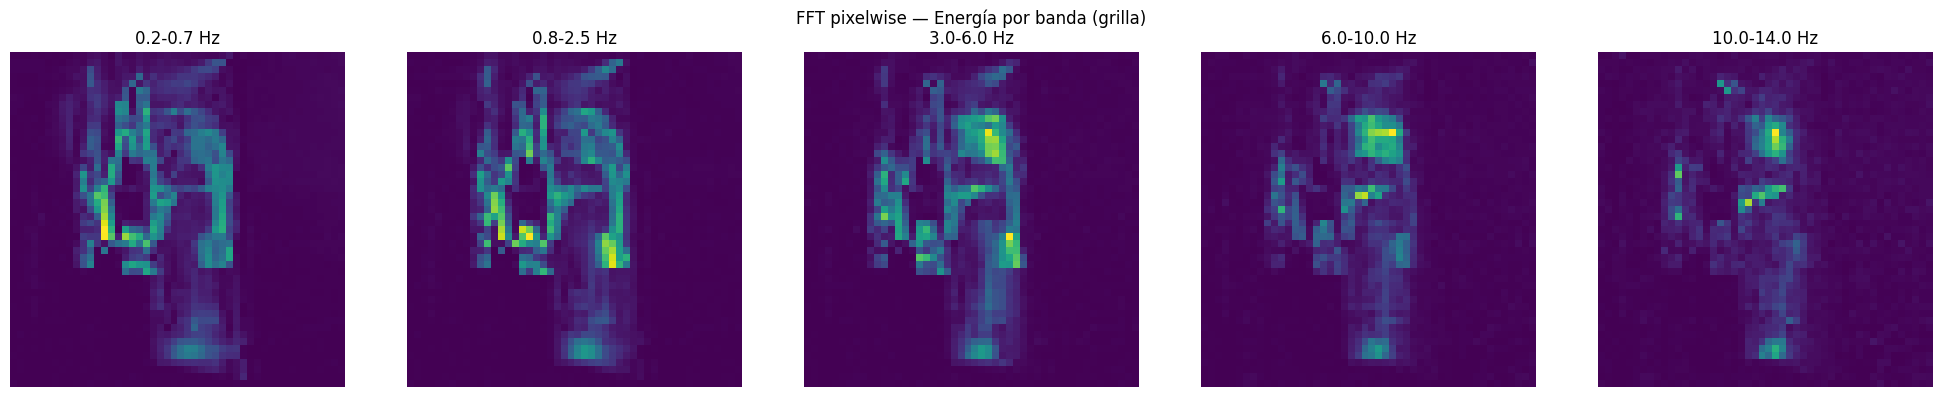

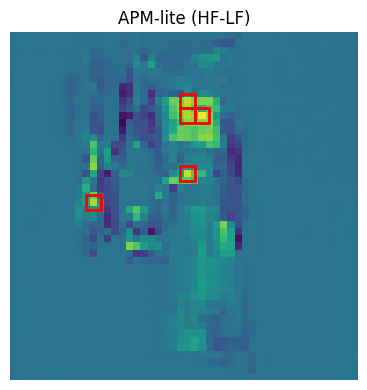

== Métricas híbridas ==
hf_lf_ratio: 0.1261
rppg_f_peak_hz: 0.9441
rppg_snr: 3.1935
ridge_std: 0.0000
spatial_coherence_rppg: 0.6669
CWT tokens: torch.Size([1, 48, 2304, 256])
FFT tokens: torch.Size([1, 48, 2304, 256])
Métricas: {'hf_lf_ratio': 0.1260833411336097, 'rppg_f_peak_hz': 0.9440874457359314, 'rppg_snr': 3.1935140354160283, 'ridge_std': 0.0, 'spatial_coherence_rppg': 0.6669271119874529}


In [13]:
VIDEO_PATH = r"C:\Deepfake\Datasets\FF++\real\01__exit_phone_room.mp4"
#VIDEO_PATH = r"C:\Deepfake\Datasets\FF++\real\01__hugging_happy.mp4"
#VIDEO_PATH = r"C:\Deepfake\Datasets\FF++\fake\01_02__exit_phone_room__YVGY8LOK.mp4"
#VIDEO_PATH = r"C:\Deepfake\Datasets\FF++\fake\01_02__hugging_happy__YVGY8LOK.mp4"

res = hybrid_analyze_video(
    VIDEO_PATH,
    target_fps=30.0,
    max_frames=48,
    resize=(192,192),
    grid=(48,48),
    cwt_cfg=dict(  # puedes dejarlo vacío para usar tus defaults
        # w0=6.5, kernel_size=95, n_bands=16, fmin=0.5, fmax=12.0,  # ejemplo para T=48
    ),
    fft_bands=((0.2,0.7),(0.8,2.5),(3.0,6.0),(6.0,10.0),(10.0,14.0)),
    visualize=True
)

print("CWT tokens:", None if res["tokens"]["cwt"] is None else res["tokens"]["cwt"].shape)
print("FFT tokens:", res["tokens"]["fft"].shape)
print("Métricas:", res["metrics"])
